In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
drive_path = Path('/content/drive/MyDrive')
print([file.name for file in drive_path.iterdir()])

['Colab Notebooks', 'Untitled spreadsheet (2).gsheet', 'Untitled spreadsheet (1).gsheet', 'To-do list.gsheet', 'Untitled spreadsheet.gsheet', 'Rice_Image_Dataset.zip', 'Rice_CNN.keras', 'Rice_CNN_2_untrained.keras', 'Rice_CNN_3.keras', 'Rice_AlexNet.keras', 'Rice_AlexNet_4epochs.keras', 'Rice_ResNet18_NoBN.keras', 'Rice_ResNet18_NOBN.keras', 'Rice_ResNet18_BN.keras', 'Rice_CNN_Final.keras', 'Rice_CNN2_untrained.keras', 'Rice_CNN3.keras', 'Rice_AlexNet_2.keras', 'Rice_AlexNet_4.keras', 'rice_cnn_pytorch.pth', 'rice_alexnet_pytorch.pth', 'Rice_AlexNet2_pytorch.pth']


In [3]:
import zipfile
from pathlib import Path
zip_path = Path("/content/drive/MyDrive/Rice_Image_Dataset.zip")
extract_path = Path("/content/Rice_Data")
with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)
print("Extraction completed!")

Extraction completed!


In [4]:
path = Path("/content/Rice_Data")
print([folder.name for folder in path.iterdir()])

['Rice_Image_Dataset.rar']


In [5]:
!apt-get install -y unrar

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [6]:
!unrar x "/content/Rice_Data/Rice_Image_Dataset.rar" "/content/Rice_Data"

Streaming output truncated to the last 5000 lines.
Extracting  /content/Rice_Data/Arborio/Arborio (550).jpg                  91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5500).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5501).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5502).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5503).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5504).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5505).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5506).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5507).jpg                 91%  OK 
Extracting  /content/Rice_Data/Arborio/Arborio (5508).jpg                 91%  OK 
Extracting  /content/Rice_Dat

In [7]:
path =Path("/content/Rice_Data")
print([folder.name for folder in path.iterdir()])

['Basmati', 'Karacadag', 'Ipsala', 'Rice_Citation_Request.txt', 'Jasmine', 'Arborio', 'S0168169921003021.pdf', 'Rice_Image_Dataset.rar']


In [8]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras import layers , Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten , BatchNormalization
from sklearn.model_selection import train_test_split

The necessary libraries are imported for file handling , image processing , data analysis , visualization and deep learning.

In [9]:
if len(tf.config.list_physical_devices('GPU')) == 0 :
    print(f"CPU is available")
else :
    print(f"GPU is available")

GPU is available


In [10]:
from pathlib import Path
from PIL import Image
path = Path("/content/Rice_Data")
for folder in path.iterdir():
    if folder.is_dir():
            images = list(folder.glob("*.jpg"))
            with Image.open(images[0]) as img:
                print(folder.name,img.size)


Basmati (250, 250)
Karacadag (250, 250)
Ipsala (250, 250)
Jasmine (250, 250)
Arborio (250, 250)


Image Dimensions are examined to understand the input image structure.
The inspected sample images from all five rice classes have a resolution of 250 x 250 pixels.

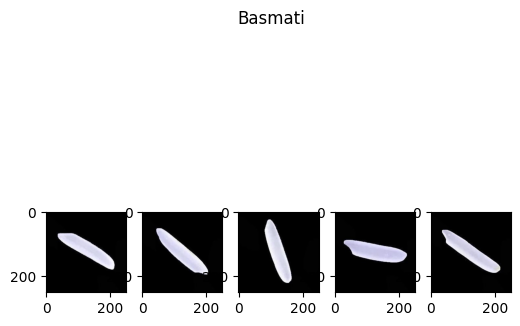

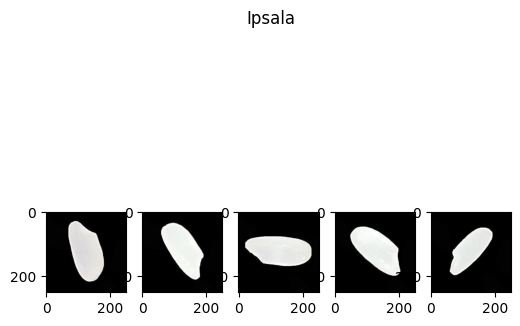

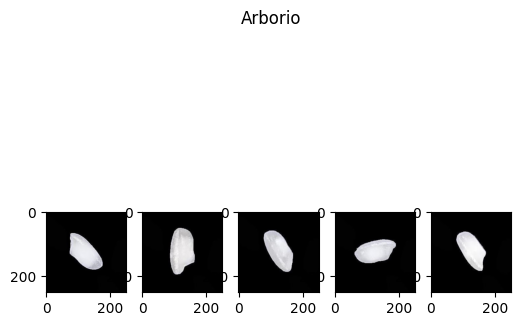

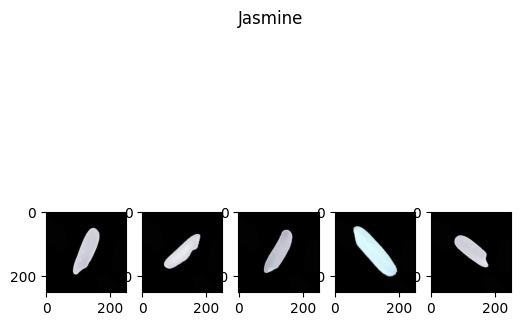

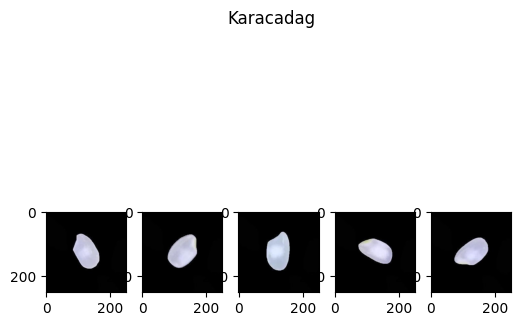

In [ ]:
for folder in path.iterdir():
    if folder.is_dir():
        images= list(folder.glob("*.jpg"))[:5]
        plt.figure(figsize=(6,5))
        for i , image in enumerate(images):
            with Image.open(image) as img:
                plt.subplot(1,5,i+1)
                plt.imshow(img)
        plt.suptitle(folder.name)
        plt.show()

Multiple sample images from each rice class are displayed using matplotlib.
This visualization helps explore the visual characteristics of different rice varities, including grain shape, size, color and texture.

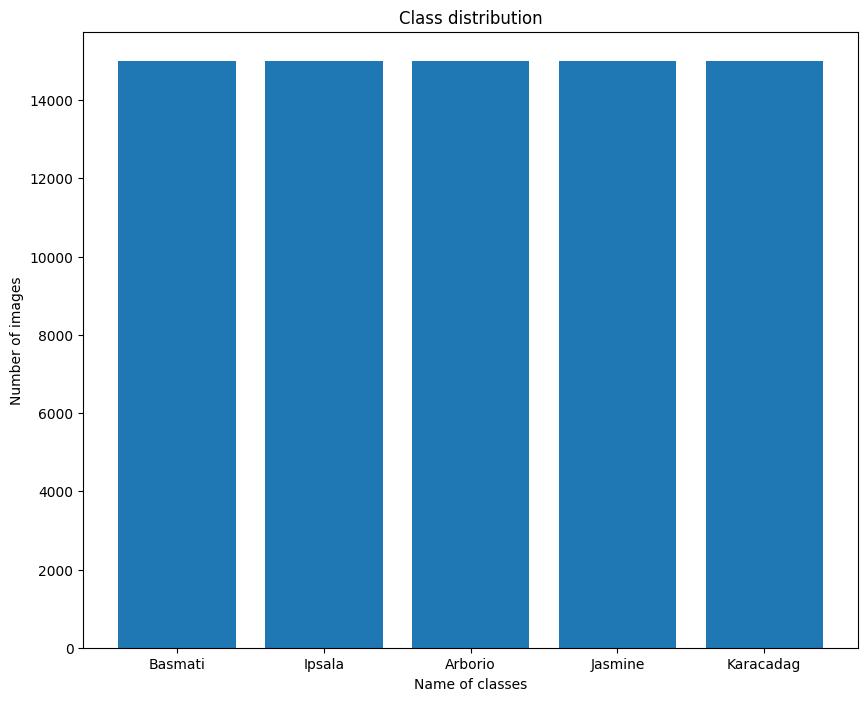

In [ ]:
class_name = []
counts = []
for folder in path.iterdir():
    if folder.is_dir():
        images = list(folder.glob("*.jpg"))
        class_name.append(folder.name)
        counts.append(len(images))
plt.figure(figsize=(10,8))
plt.bar(class_name,counts)
plt.xlabel("Name of classes")
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.show()

A bar chart was used to visualize the number of images in each rice category.
All five classes contain an equal number of images including that the dataset is balanced.

In [11]:
df = []
classes = sorted([folder.name for folder in path.iterdir() if folder.is_dir()])
for label , class_name in enumerate(classes):
    folder = path / class_name
    for image in folder.glob("*.jpg"):
        df.append([str(image),class_name,label])
    dataframe = pd.DataFrame(df,columns=['Image_Path','Class','Label'])
dataframe.head()

,Image_Path,Class,Label
0,/content/Rice_Data/Arborio/Arborio (14656).jpg,Arborio,0
1,/content/Rice_Data/Arborio/Arborio (9427).jpg,Arborio,0
2,/content/Rice_Data/Arborio/Arborio (8886).jpg,Arborio,0
3,/content/Rice_Data/Arborio/Arborio (7774).jpg,Arborio,0
4,/content/Rice_Data/Arborio/Arborio (10675).jpg,Arborio,0


A pandas dataframe is created to organize the dataset information.
Image paths are sorted instead of loading all image pixel data into memory.

In [12]:
dataframe.shape

(75000, 3)

The dataframe shape is (75000,3) representing 75000 images and 3 columns.

In [13]:
dataframe.isnull().sum()

,0
Image_Path,0
Class,0
Label,0


No missing values were detected.

In [14]:
train_size = int(0.8*len(dataframe))
valid_size = int(0.1*len(dataframe))
test_size = len(dataframe)-train_size-valid_size
print(train_size)
print(valid_size)
print(test_size)

60000
7500
7500


The dataset was divided into three subsets: Training - Validation - Testing
Training Set (80%) : Used to train the model.
Validation Set (10%) : Used to monitor model performance.
Test Set (10%): Used for the final evaluation of model performance on unseen images.

In [15]:
dataframe = dataframe.sample(frac=1,random_state=42).reset_index(drop=True)

The dataframe was randomly shuffled before splitting to reduce ordering bias and mix images from different rice classes.

In [16]:
train_df = dataframe.iloc[:train_size]
valid_df = dataframe.iloc[train_size:train_size+valid_size]
test_df = dataframe.iloc[train_size + valid_size:]

The shuffled dataframe was divided into three subsets using pandas iloc indexing.

In [17]:
print("Train:",train_df.shape)
print("Test:",test_df.shape)
print("Valid:",valid_df.shape)

Train: (60000, 3)
Test: (7500, 3)
Valid: (7500, 3)


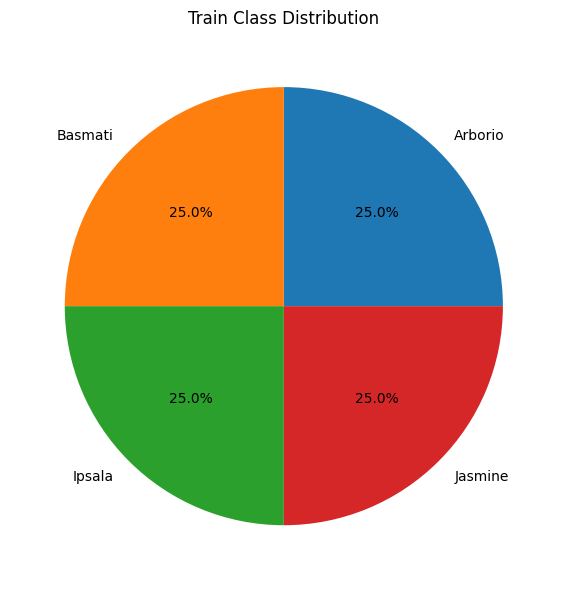

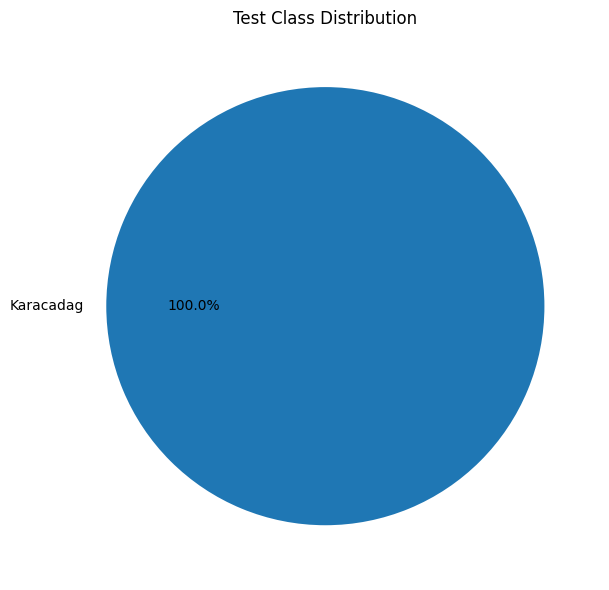

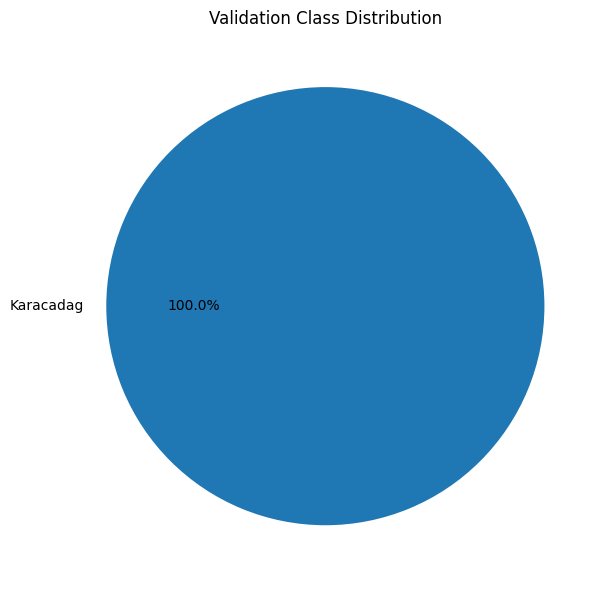

In [ ]:
plt.figure(figsize=(8,6))
train_df['Class'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.title("Train Class Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))
test_df['Class'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.title("Test Class Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))
valid_df['Class'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.title("Validation Class Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

Pie charts were used to visualize the percentage distribution of the five rice classes within each dataset subset.
The training , validation and test sets show approximately balanced class distributions. Each rice variety represents around 20% of the samples in each subset.

In [ ]:
train_generator = ImageDataGenerator(rescale=1./255)
valid_generator = ImageDataGenerator(rescale=1./255)
test_generator = ImageDataGenerator(rescale=1./255)

The ImageDataGenerator class from Tensorflow was used to preper image batches for CNN training and evaluation.
A rescaling factor of 1/255 was applied to convert pixel values from the original range to [0,1].

In [ ]:
train_generator = train_generator.flow_from_dataframe(dataframe=train_df,x_col='Image_Path',y_col='Class',target_size=(224,224),
                                                      batch_size=32,class_mode='categorical',shuffle=True)
valid_generator = valid_generator.flow_from_dataframe(dataframe=valid_df,x_col='Image_Path',y_col='Class',target_size=(224,224),
                                                      batch_size=32,class_mode='categorical',shuffle=False)
test_generator = test_generator.flow_from_dataframe(dataframe=test_df,x_col='Image_Path',y_col='Class',target_size=(224,224),
                                                      batch_size=32,class_mode='categorical',shuffle=False)

Found 60000 validated image filenames belonging to 5 classes.
Found 7500 validated image filenames belonging to 5 classes.
Found 7500 validated image filenames belonging to 5 classes.


**Training Data Generator**:
Loads training images in batches of 32, resizes them to 224 × 224, and applies normalization.
• Class Mode: Categorical
• Shuffle: True
• Purpose: Model training and weight optimization.
**Validation Data Generator**:
Loads normalized validation images in batches of 32 with a size of 224 × 224.
• Class Mode: Categorical
• Shuffle: False
• Purpose: Monitoring model performance during training.
**Test Data Generator**:
Loads normalized test images in batches of 32 with a size of 224 × 224.
• Class Mode: Categorical
• Shuffle: False
• Purpose: Final model evaluation on unseen images.

In [ ]:
print(train_generator.class_indices)
print(valid_generator.class_indices)
print(test_generator.class_indices)

{'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}
{'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}
{'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}


In [ ]:
X_batch , Y_batch = next(train_generator)
print("Images:",X_batch.shape)
print("Labels:",Y_batch.shape)

Images: (32, 224, 224, 3)
Labels: (32, 5)


A sample batch was extracted to verify the image dimensions and one-hot encoded labels before CNN model development.

In [ ]:
Model = Sequential([layers.Input(shape=(224,224,3)),
                    layers.Conv2D(32,(3,3),activation='relu',padding='same'),
                    layers.MaxPool2D(2,2),
                    layers.Conv2D(64,(3,3),activation='relu',padding='same'),
                    layers.MaxPool2D(2,2),
                    layers.Conv2D(128,(3,3),activation='relu',padding='same'),
                    layers.MaxPool2D(2,2),
                    layers.Flatten(),
                    layers.Dense(128,activation='relu'),
                    layers.Dense(5,activation='softmax')])
Model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,077 (49.36 MB)

 Trainable params: 12,939,077 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

A sequential CNN model was built using TensorFlow for rice image classification.
The architecture includes 3 convolutional blocks with 32,64 and 128 filters , followed by MaxPooling layers for feature extraction and dimensionality redcution.
Flatten and Dense layers were used for classification with a final softmax layer containing 5 output neurons.

In [ ]:
Model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

The CNN model was compiled using the Adam optimizer , Categorical Crossentropy loss and Accuracy metric for 5 class rice classification.

In [ ]:
history = Model.fit(train_generator,validation_data=valid_generator,epochs=2)

Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 201s 102ms/step - accuracy: 0.9571 - loss: 0.1261 - val_accuracy: 0.9688 - val_loss: 0.0977
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 161s 86ms/step - accuracy: 0.9743 - loss: 0.0748 - val_accuracy: 0.9637 - val_loss: 0.1052


The CNN model is trained for 2 epochs using the training dataset.

In [ ]:
Model.save('/content/drive/MyDrive/Rice_CNN_Final.keras')

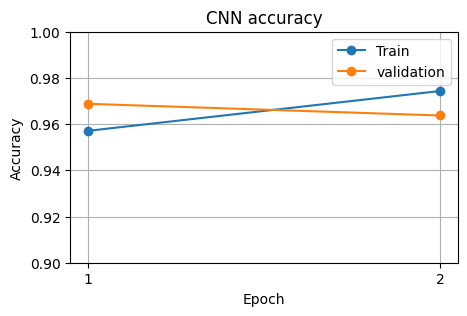

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(history.history['accuracy'],marker='o',label='Train')
plt.plot(history.history['val_accuracy'],marker='o',label='validation')
plt.title("CNN accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([0,1],[1,2])
plt.ylim([0.9,1.00])
plt.legend()
plt.grid(True)
plt.show()

Training and validation accuracy were plotted to monitor the model's learning progress and generalization performance.
Training accuracy increased while Validation accuracy decreased.

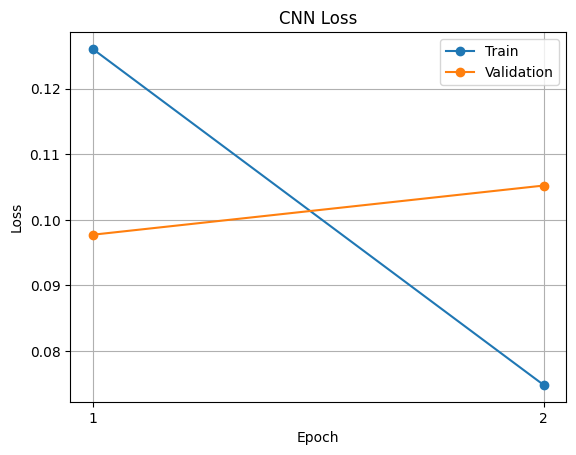

In [ ]:
plt.plot(history.history['loss'],marker='o',label='Train')
plt.plot(history.history['val_loss'],marker='o',label='Validation')
plt.title('CNN Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([0,1],[1,2])
plt.legend()
plt.grid(True)
plt.show()

Training and validation loss were plotted to evaluate learning behavior and identify possible overfitting.
Training loss decreased while validation loss increased.

In [ ]:
test_generator.reset()
test_loss , test_accuracy = Model.evaluate(test_generator)
print("Test Loss:",test_loss)
print("Test Accuracy:", test_accuracy)

235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step - accuracy: 0.9672 - loss: 0.0974
Test Loss: 0.09742525219917297
Test Accuracy: 0.967199981212616


The trained CNN was evaluated on the test dataset achieving **96.71%** accuracy and a test loss of **0.0974**.

In [ ]:
test_generator.reset()
y_prob = Model.predict(test_generator)
y_pred = np.argmax(y_prob,axis=1)
y_true = test_generator.classes

235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step


The CNN predicts rice classes on the test dataset. Predicted labels were compared with actual labels.

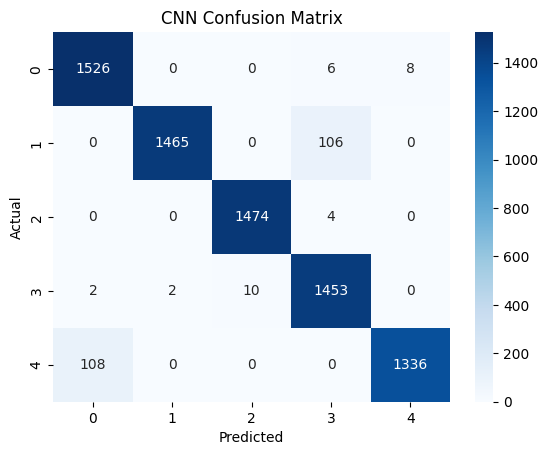

In [ ]:
cm = confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

The CNN correctly classified 7254 out of 7500 test images.
Class 2 demonstrated excellent classification performance.

In [ ]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      1540
           1       1.00      0.93      0.96      1571
           2       0.99      1.00      1.00      1478
           3       0.93      0.99      0.96      1467
           4       0.99      0.93      0.96      1444

    accuracy                           0.97      7500
   macro avg       0.97      0.97      0.97      7500
weighted avg       0.97      0.97      0.97      7500



Class 2 achieved the highest F1-score of 1.00.


In [ ]:
model_2 = Sequential([layers.Input(shape=(224,224,3)),
                    layers.Conv2D(32,(3,3),padding='same'),layers.BatchNormalization(),layers.Activation('relu'),layers.MaxPooling2D((2,2)),
                    layers.Conv2D(64,(3,3),padding='same'),layers.BatchNormalization(),layers.Activation('relu'),
                    layers.Conv2D(64,(3,3),padding='same'),layers.BatchNormalization(),layers.Activation('relu'),layers.MaxPooling2D((2,2)),
                    layers.Conv2D(128,(3,3),padding='same'),layers.BatchNormalization(),layers.Activation('relu'),
                    layers.Conv2D(128,(3,3),padding='same'),layers.BatchNormalization(),layers.Activation('relu'),
                    layers.MaxPooling2D((2,2)),layers.Dropout(0.2),
                    layers.GlobalAveragePooling2D(),
                    layers.Dense(64,activation='relu'),
                    layers.Dense(5,activation='softmax')])

A new CNN architecture was developed using 3 convolutional blocks with 32,64 and 128 filters. BatchNormalization was added to improve train stability while dropout was used for regularization. GlobalAveragePooling2D replaced Flatten to reduce the number of trainable parameters.

In [ ]:
model_2.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

The model was compiled using the adam optimizer , categorical crossentropy loss and accuracy as the evaluation metric.

In [ ]:
model_2.fit(train_generator,validation_data=valid_generator,epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 265s 129ms/step - accuracy: 0.9473 - loss: 0.1687 - val_accuracy: 0.2060 - val_loss: 19.2980
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 231s 123ms/step - accuracy: 0.9819 - loss: 0.0572 - val_accuracy: 0.3952 - val_loss: 6.0770
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 234s 125ms/step - accuracy: 0.9877 - loss: 0.0381 - val_accuracy: 0.3191 - val_loss: 9.0316


The CNN was trained for 3 epochs using the training and validation datasets. Training accuracy reached 98.77% while validation accuracy dropped to 31.91 indicating a significant generalization or evaluation issue.

In [ ]:
model_2.save('/content/drive/MyDrive/Rice_CNN2_untrained.keras')

In [ ]:
train_loss , train_acc = model_2.evaluate(train_generator)
print("Train Evaluation Accuracy:",train_acc)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 151s 80ms/step - accuracy: 0.3106 - loss: 9.1575
Train Evaluation Accuracy: 0.31060001254081726


The model was evaluated on the training dataset in inference mode.
Despite achieving 98.77% accuracy during training , evaluation accuracy dropped to 31.06% with a loss of 9.1575.
This significant difference suggests a possible issue with training and inference behavior , potentially related to BatchNormalization.

In [ ]:
test_loss , test_acc = model_2.evaluate(test_generator)
print("Test Accuracy:",test_acc)
print("Test Loss:",test_loss)

235/235 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.3087 - loss: 9.1265
Test Accuracy: 0.3086666762828827
Test Loss: 9.126545906066895


The model achieved a test accuracy of 30.87% and a test loss of 9.1265.
This similar results on the training and test datasets in inference model suggest an evaluation-related instability, potentially associated with Batch Normalization.

In [ ]:
model_3 = Sequential([layers.Input(shape=(224,224,3)),
                    layers.Conv2D(32,(3,3),padding='same'),layers.Activation('relu'),layers.MaxPooling2D((2,2)),
                    layers.Conv2D(64,(3,3),padding='same'),layers.Activation('relu'),
                    layers.Conv2D(64,(3,3),padding='same'),layers.Activation('relu'),layers.MaxPooling2D((2,2)),
                    layers.Conv2D(128,(3,3),padding='same'),layers.Activation('relu'),
                    layers.Conv2D(128,(3,3),padding='same'),layers.Activation('relu'),
                    layers.MaxPooling2D((2,2)),layers.Dropout(0.2),
                    layers.GlobalAveragePooling2D(),
                    layers.Dense(64,activation='relu'),
                    layers.Dense(5,activation='softmax')])

A third CNN was developed using the same architecture as model 2 but without BatchNormalization layers.
The goal was to investigate whether removing BatchNormalization would improve validation performance.

In [ ]:
model_3.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

The model was compiled using the adam optimizer , categorical crossentropy loss and accuracy of the evaluation matrix.

In [ ]:
model_3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,341 (1.09 MB)

 Trainable params: 286,341 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_3.fit(train_generator,validation_data=valid_generator,epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 205s 107ms/step - accuracy: 0.8444 - loss: 0.3689 - val_accuracy: 0.9711 - val_loss: 0.0894
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 202s 108ms/step - accuracy: 0.9716 - loss: 0.0833 - val_accuracy: 0.9032 - val_loss: 0.3049
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 206s 110ms/step - accuracy: 0.9787 - loss: 0.0677 - val_accuracy: 0.9780 - val_loss: 0.0645


The model was trained for 3 epochs.
Train accuracy increased while validation accuracy improved.

In [ ]:
model_3.save('/content/drive/MyDrive/Rice_CNN3.keras')

In [ ]:
train_loss , train_acc = model_3.evaluate(train_generator)
print("Train Evaluation Accuracy:",train_acc)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 143s 76ms/step - accuracy: 0.9766 - loss: 0.0677
Train Evaluation Accuracy: 0.9766499996185303


Both training and validation accuracy increased across the three epochs.

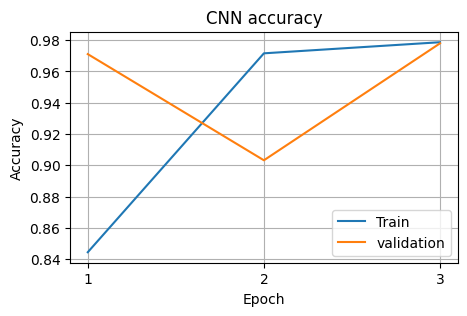

In [ ]:
plt.figure(figsize=(5,3))
train_acc = [0.8444 , 0.9716 , 0.9787]
val_acc = [0.9711 , 0.9032 , 0.9780]
plt.plot([1,2,3],train_acc,label='Train')
plt.plot([1,2,3],val_acc,label='validation')
plt.title("CNN accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)
plt.show()

The model achieved strong training and validation accuracy, with no clear evidence of severe overfitting at the end of training.

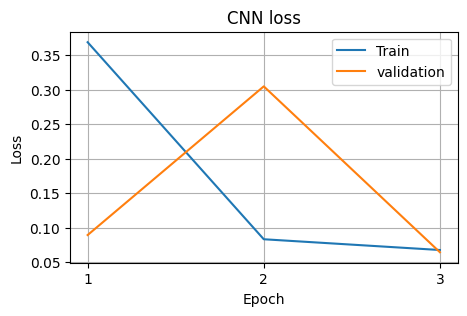

In [ ]:
plt.figure(figsize=(5,3))
train_loss = [0.3689 , 0.0833 , 0.0677]
val_loss = [0.0894 , 0.3049 , 0.0645]
plt.plot([1,2,3],train_loss,label='Train')
plt.plot([1,2,3],val_loss,label='validation')
plt.title("CNN loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)
plt.show()

Despite temporary fluctuations, both losses were low at the end of training , suggesting improved model performance.

In [ ]:
model_3 = load_model('/content/drive/MyDrive/Rice_CNN3.keras')

In [ ]:
test_loss , test_acc = model_3.evaluate(test_generator)
print("Test Accuracy:" , test_acc)
print("Test Loss:" , test_loss)

235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 80ms/step - accuracy: 0.9775 - loss: 0.0632
Test Accuracy: 0.9774666428565979
Test Loss: 0.06320353597402573


The model achieved 97.74% accuracy on the independent test dataset with a test loss of 0.0716.
Training, validation and test accuracies were closely aligned indicating good generalization to unseen images.

In [ ]:
test_generator.reset()
y_prob = model_3.predict(test_generator)
y_pred = np.argmax(y_prob,axis=1)
y_true = test_generator.classes

235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 91ms/step


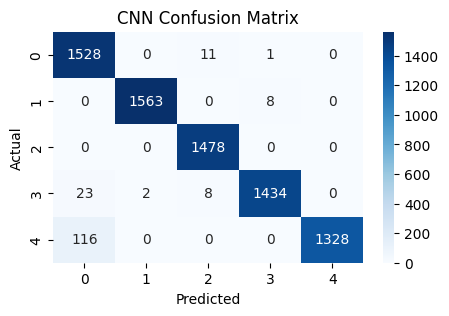

In [ ]:
plt.figure(figsize=(5,3))
cm = confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

The model correctly classified 7331 out of 7500 test images.
Class 2 achieved perfect recall with all 1478 images correctly classified.

In [ ]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95      1540
           1       1.00      0.99      1.00      1571
           2       0.99      1.00      0.99      1478
           3       0.99      0.98      0.99      1467
           4       1.00      0.92      0.96      1444

    accuracy                           0.98      7500
   macro avg       0.98      0.98      0.98      7500
weighted avg       0.98      0.98      0.98      7500



Class 1, 2 and 3 demonstarted excellent classification performance with F1 Scores of approximatelt 0.99-1.00.
Class 4 had the lowest recall.

In [ ]:
model_4 = Sequential([layers.Input(shape=(224,224,3)),
                      layers.Conv2D(96,kernel_size=(11,11),strides=4,padding='valid',activation='relu'),
                      layers.MaxPooling2D(pool_size=(3,3),strides=2),
                      layers.Conv2D(256,kernel_size=(5,5),strides=1,padding='same',activation='relu'),
                      layers.MaxPooling2D(pool_size=(3,3),strides=2),
                      layers.Conv2D(384,kernel_size=(3,3),strides=1,padding='same',activation='relu'),
                      layers.Conv2D(384,(3,3),padding='same',activation='relu'),
                      layers.Conv2D(256,kernel_size=(3,3),padding='same',activation='relu'),
                      layers.MaxPooling2D(pool_size=(3,3),strides=2),
                      layers.Flatten(),
                      layers.Dense(4096,activation='relu'),
                      layers.Dropout(0.5),
                      layers.Dense(4096,activation='relu'),
                      layers.Dropout(0.5),
                      layers.Dense(5,activation='softmax')])

An AlexNet implemented for classifying five rice varities.
The model uses five convolustional layers with 96 , 256 , 384 and 256 filters , followed by maxpooling and fully connected layers.
The input image size is 224x224x3 and the output layer contains five neurons with softmax activation.

In [ ]:
model_4.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │        20,485 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,767,493 (178.40 MB)

 Trainable params: 46,767,493 (178.40 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_4.compile(optimizer=SGD(learning_rate=0.001,momentum=0.9),loss='categorical_crossentropy',metrics=['accuracy'])

The model was compiled using SGD with a learning rate of 0.001 and momentum of 0.9.
Categorical crossentropy was selected as the loss function and accuracy was used as the evaluation metric.

In [ ]:
history_4 = model_4.fit(train_generator , validation_data = valid_generator , epochs=2)

Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 172s 85ms/step - accuracy: 0.8690 - loss: 0.3274 - val_accuracy: 0.9584 - val_loss: 0.1165
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 159s 85ms/step - accuracy: 0.9623 - loss: 0.1154 - val_accuracy: 0.9643 - val_loss: 0.1042


The model was trained for 2 epochs.
Training accuracy increased while validation accuracy improved.
Validation loss decreased.

In [ ]:
model_4.save('/content/drive/MyDrive/Rice_AlexNet_2.keras')

In [ ]:
train_loss , train_acc = model_4.evaluate(train_generator)
print("Train Evaluation Accuracy:",train_acc)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 125s 67ms/step - accuracy: 0.9690 - loss: 0.0961
Train Evaluation Accuracy: 0.9689666628837585


The AlexNet model achieved 96.90% accuracy and a loss of 0.0961 when evaluated on the training dataset.


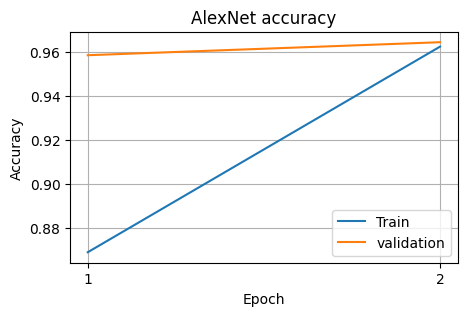

In [ ]:
plt.figure(figsize=(5,3))
train_acc = [0.8690,0.9623]
val_acc = [0.9584,0.9643]
plt.plot([1,2],train_acc,label='Train')
plt.plot([1,2],val_acc,label='validation')
plt.title("AlexNet accuracy")
plt.xticks([1,2])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Training accuracy increased over two epochs.
validation accuracy improved too.

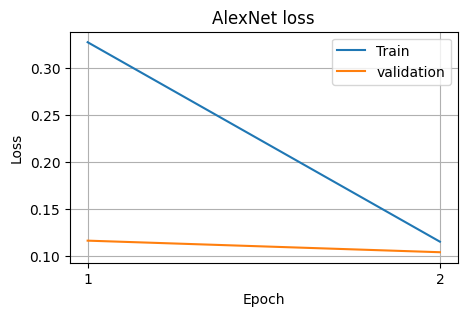

In [ ]:
plt.figure(figsize=(5,3))
train_loss = [0.3274,0.1154]
val_loss = [0.1165, 0.1042]
plt.plot([1,2],train_loss,label='Train')
plt.plot([1,2],val_loss,label='validation')
plt.title("AlexNet loss")
plt.xticks([1,2])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Both training loss and validation loss decreased.

In [ ]:
test_loss , test_acc = model_4.evaluate(test_generator)
print("Test Accuracy:",test_acc)
print("Test Loss:" , test_loss)

235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.9661 - loss: 0.1026
Test Accuracy: 0.9661333560943604
Test Loss: 0.10257264226675034


The Alexnet model achieved a test accuracy of 96.61% and a test loss 0.1026 on 7500 test images.

In [ ]:
test_generator.reset()

In [ ]:
y_prob = model_4.predict(test_generator)
y_pred = np.argmax(y_prob,axis=1)
y_true = test_generator.classes

235/235 ━━━━━━━━━━━━━━━━━━━━ 17s 71ms/step


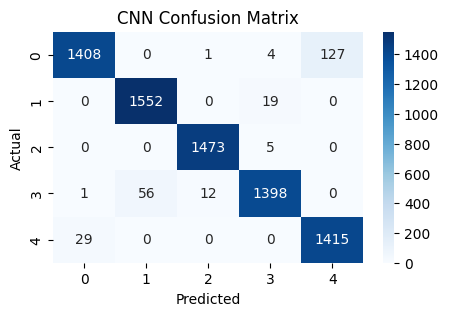

In [ ]:
plt.figure(figsize=(5,3))
cm = confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("AlexNet Confusion Matrix")
plt.show()

The AlexNet model correctly classified 7246 out of 7500 test images.
Class 2 demonstrated excellent classification performance.

In [ ]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.91      0.95      1540
           1       0.97      0.99      0.98      1571
           2       0.99      1.00      0.99      1478
           3       0.98      0.95      0.97      1467
           4       0.92      0.98      0.95      1444

    accuracy                           0.97      7500
   macro avg       0.97      0.97      0.97      7500
weighted avg       0.97      0.97      0.97      7500



Class 2 achieved the strongest classification performance with and F1-Score of 0.99.
Class 0 had the lowest recall.

In [ ]:
history_4_extra = model_4.fit(train_generator,validation_data=valid_generator,epochs=2)

Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 150s 80ms/step - accuracy: 0.9661 - loss: 0.0994 - val_accuracy: 0.9661 - val_loss: 0.0997
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 145s 77ms/step - accuracy: 0.9697 - loss: 0.0893 - val_accuracy: 0.9668 - val_loss: 0.0992


After the initial two epochs , the model was trained for two additional epochs using the same training and validation datasets.
The purpose was to investigate wheter additional training could improve classification accuracy and reduce validation loss.
Training accuracy improved across both epochs. Validation accuracy decreased slightly in Epoch 4, while validation loss continued to decrease.

In [ ]:
model_4.save('/content/drive/MyDrive/Rice_AlexNet_4.keras')

In [ ]:
train_loss , train_acc = model_4.evaluate(train_generator)
print("Train Evaluation Accuracy:",train_acc)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 145s 77ms/step - accuracy: 0.9690 - loss: 0.0943
Train Evaluation Accuracy: 0.9689833521842957


After completing four epochs , the model was evaluated on the training dataset in inference model.
The training evaluation accuracy was close to the final validation accuracy.

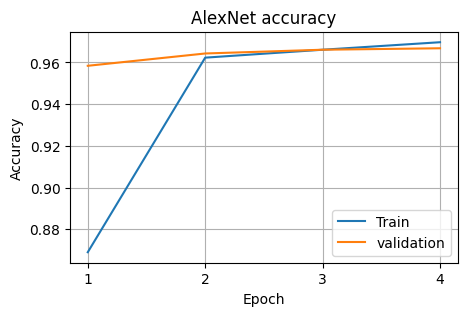

In [ ]:
plt.figure(figsize=(5,3))
train_acc = [0.8690,0.9623,0.9661,0.9697]
val_acc = [0.9584,0.9643,0.9661,0.9668]
plt.plot([1,2,3,4],train_acc,label='Train')
plt.plot([1,2,3,4],val_acc,label='validation')
plt.title("AlexNet accuracy")
plt.xticks([1,2,3,4])
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Both curves indicate good learning performance , with a small gap between training and validation accuracy suggesting no clear signs of severe overfitting.

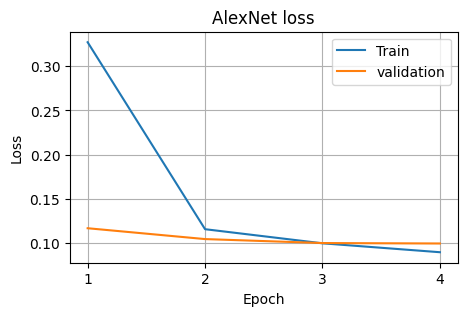

In [ ]:
plt.figure(figsize=(5,3))
train_loss = [0.3274,0.1154,0.0994,0.0893]
val_loss = [0.1165,0.1042,0.0997,0.0992]
plt.plot([1,2,3,4],train_loss,label='Train')
plt.plot([1,2,3,4],val_loss,label='validation')
plt.title("AlexNet loss")
plt.xticks([1,2,3,4])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Both curves show a downward trend, indicating improved model performance without clear signs of overfitting.

In [ ]:
test_loss , test_acc = model_4.evaluate(test_generator)
print("Test Accuracy:",test_acc)
print("Test Loss:" , test_loss)

235/235 ━━━━━━━━━━━━━━━━━━━━ 15s 65ms/step - accuracy: 0.9696 - loss: 0.0938
Test Accuracy: 0.9696000218391418
Test Loss: 0.09384968876838684


The model was evaluated on an independent test dataset containing 7500 images.
Compared with the two-epoch version the four-epoch model showed a modest improvement in test performance.

In [ ]:
test_generator.reset()
y_prob = model_4.predict(test_generator)
y_pred = np.argmax(y_prob,axis=1)
y_true = test_generator.classes


235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step


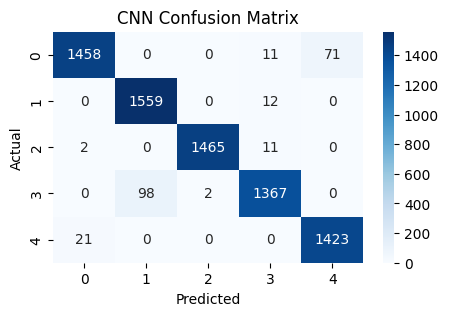

In [ ]:
plt.figure(figsize=(5,3))
cm = confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("AlexNet Confusion Matrix")
plt.show()

Of the 7500 test images , 7272 were correctly classified corresponding to an accuracy of approximately **96.96%**.

In [ ]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.95      0.97      1540
           1       0.94      0.99      0.97      1571
           2       1.00      0.99      0.99      1478
           3       0.98      0.93      0.95      1467
           4       0.95      0.99      0.97      1444

    accuracy                           0.97      7500
   macro avg       0.97      0.97      0.97      7500
weighted avg       0.97      0.97      0.97      7500



Class 2 achieved the strongest overall performance with an F1-Score close to 1.00.
Class had the lowest recall and F1 Score indicating greater difficulty in correctly identifying this class.

In [ ]:
def residual_block(X,filters,stride=1):
  shortcut = X
  X = layers.Conv2D(filters,3,strides=stride,padding='same')(X)
  X = layers.BatchNormalization()(X)
  X = layers.ReLU()(X)
  X = layers.Conv2D(filters,3,padding='same')(X)
  X = layers.BatchNormalization()(X)
  if stride != 1 or shortcut.shape[1] != filters:
    shortcut = layers.Conv2D(filters,1,strides=stride)(shortcut)
    shortcut = layers.BatchNormalization()(shortcut)
  X = layers.Add()([X,shortcut])
  return layers.ReLU()(X)
inputs = layers.Input(shape=(224,224,3))
X = layers.Conv2D(64,7,strides=2,padding='same')(inputs)
X = layers.BatchNormalization()(X)
X = layers.ReLU()(X)
X = layers.MaxPooling2D(3,strides=2,padding='same')(X)
X = residual_block(X,64)
X = residual_block(X,64)
X = residual_block(X,128,stride=2)
X = residual_block(X,128)
X = residual_block(X,256,stride=2)
X = residual_block(X,256)
X = residual_block(X,512,stride=2)
X = residual_block(X,512)
X = layers.GlobalAveragePooling2D()(X)
outputs = layers.Dense(5,activation='softmax')(X)
model_5 = Model(inputs,outputs,name='Resnet18')
model_5.summary()




Model: "Resnet18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 112, 112,  │      9,472 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_17 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ re_lu_17[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 56, 56,    │     36,928 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_26[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 56, 56,    │     36,928 │ re_lu_18[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 56, 56,    │      4,160 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_27[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_28[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 56, 56,    │          0 │ add_8[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 56, 56,    │     36,928 │ re_lu_19[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_29[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat

 Total params: 11,550,853 (44.06 MB)

 Trainable params: 11,539,205 (44.02 MB)

 Non-trainable params: 11,648 (45.50 KB)

ResNet 18 is a CNN with 18 main learnable layers and skip connections that improve gradient flow.
The model consists of :
Input : 224x224x3
Initial Layers: Conv2D(7x7)
BatchNormalization,ReLu,MaxPooling
Residual Stages: 4 stages with 2 residual blocks each , using 64,128,256 and 512 filters
Skip Connections: Identity or 1x1 projection shotcuts to macth dimensions
Classification : GlobalAveragePooling2D followd by Dense(5,softmax).

In [ ]:
model_5.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                loss = 'categorical_crossentropy',
                metrics=['accuracy'])

The model was compiled using the Adam optimizer with a learning rate of 0.001.
Categorical CrossEntropy was used for five classification and accuracy was selected as the evaluation metric.

In [ ]:
history_5 = model_5.fit(train_generator,validation_data = valid_generator , epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 297s 136ms/step - accuracy: 0.9697 - loss: 0.0867 - val_accuracy: 0.8592 - val_loss: 0.4256
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 252s 135ms/step - accuracy: 0.9876 - loss: 0.0364 - val_accuracy: 0.3616 - val_loss: 11.3493
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 252s 134ms/step - accuracy: 0.9885 - loss: 0.0338 - val_accuracy: 0.8592 - val_loss: 0.3835


The model was configured to train for 3 epochs.

In [ ]:
train_loss , train_acc = model_5.evaluate(train_generator)
print("Train accuracy:",train_acc)
print("Train loss:" , train_loss)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 132s 70ms/step - accuracy: 0.8624 - loss: 0.3801
Train accuracy: 0.8623666763305664
Train loss: 0.380105584859848


The model was evaluated on the training dataset in inference mode:
Accuracy : 86.24%
Loss : 0.3801

In [ ]:
model_5.save('/content/drive/MyDrive/Rice_ResNet18_BN.keras')

In [ ]:
test_loss , test_acc = model_5.evaluate(test_generator)
print("Test Accuracy:" , test_acc)
print("Test Loss:", test_loss)

235/235 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - accuracy: 0.8572 - loss: 0.4148
Test Accuracy: 0.857200026512146
Test Loss: 0.4148178994655609


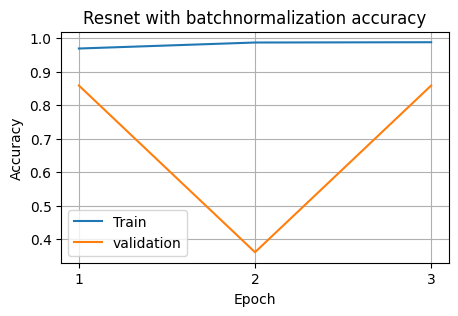

In [ ]:
plt.figure(figsize=(5,3))
train_acc = history_5.history['accuracy']
val_acc = history_5.history['val_accuracy']
plt.plot([1,2,3],train_acc,label='Train')
plt.plot([1,2,3],val_acc,label='validation')
plt.title("Resnet with batchnormalization accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)
plt.show()

This plot indicates unstable validation performance and a large gap between training and validation accuracy.
The instability may be related to BatchNormalization behavior during inference, although further investigation is needed to confirm the cause.

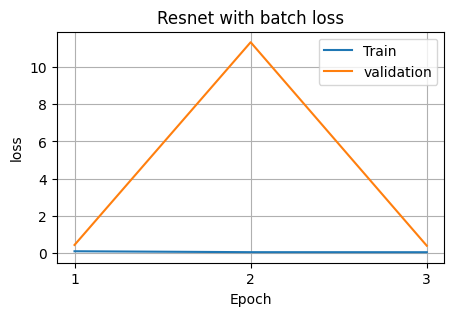

In [ ]:
plt.figure(figsize=(5,3))
train_loss = history_5.history['loss']
val_loss = history_5.history['val_loss']
plt.plot([1,2,3],train_loss,label='Train')
plt.plot([1,2,3],val_loss,label='validation')
plt.title("Resnet with batch loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)
plt.show()

This plot indicates highly unstable validation performance despite improving training loss.

In [ ]:
test_generator.reset()
y_prob = model_5.predict(test_generator)
y_pred = np.argmax(y_prob,axis=1)
y_true = test_generator.classes

235/235 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step


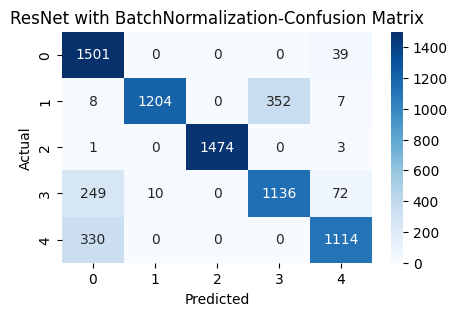

In [ ]:
plt.figure(figsize=(5,3))
cm = confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet with BatchNormalization-Confusion Matrix")
plt.show()

The model correctly classified 6429 out of 7500 test images.
Class 2 showed the strongest performance.

In [ ]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.97      0.83      1540
           1       0.99      0.77      0.86      1571
           2       1.00      1.00      1.00      1478
           3       0.76      0.77      0.77      1467
           4       0.90      0.77      0.83      1444

    accuracy                           0.86      7500
   macro avg       0.88      0.86      0.86      7500
weighted avg       0.88      0.86      0.86      7500



Class 2 showed the best performance achieving an F1-Score of 1.00.

In [ ]:
def residual_block_no_batch(X,filters,stride=1):
  shortcut = X
  X = layers.Conv2D(filters,3,strides=stride,padding='same')(X)
  X = layers.ReLU()(X)
  X = layers.Conv2D(filters,3,padding='same')(X)
  if stride != 1 or shortcut.shape[1] != filters:
    shortcut = layers.Conv2D(filters,1,strides=stride)(shortcut)
  X = layers.Add()([X,shortcut])
  return layers.ReLU()(X)
inputs = layers.Input(shape=(224,224,3))
X = layers.Conv2D(64,7,strides=2,padding='same')(inputs)
X = layers.ReLU()(X)
X = residual_block_no_batch(X,64)
X = residual_block_no_batch(X,64)
X = residual_block_no_batch(X,128,stride=2)
X = residual_block_no_batch(X,128)
X = residual_block_no_batch(X,256,stride=2)
X = residual_block_no_batch(X,256)
X = residual_block_no_batch(X,512,stride=2)
X = residual_block_no_batch(X,512)
X = layers.GlobalAveragePooling2D()(X)
outputs = layers.Dense(5,activation='softmax')(X)
model_6 = Model(inputs,outputs,name='Resnet18')
model_6.summary()




Model: "Resnet18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_50 (Conv2D)  │ (None, 112, 112,  │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_34 (ReLU)     │ (None, 112, 112,  │          0 │ conv2d_50[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_51 (Conv2D)  │ (None, 112, 112,  │     36,928 │ re_lu_34[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_35 (ReLU)     │ (None, 112, 112,  │          0 │ conv2d_51[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_52 (Conv2D)  │ (None, 112, 112,  │     36,928 │ re_lu_35[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_53 (Conv2D)  │ (None, 112, 112,  │      4,160 │ re_lu_34[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 112, 112,  │          0 │ conv2d_52[0][0],  │
│                     │ 64)               │            │ conv2d_53[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_36 (ReLU)     │ (None, 112, 112,  │          0 │ add_16[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (None, 112, 112,  │     36,928 │ re_lu_36[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_37 (ReLU)     │ (None, 112, 112,  │          0 │ conv2d_54[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_55 (Conv2D)  │ (None, 112, 112,  │     36,928 │ re_lu_37[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_56 (Conv2D)  │ (None, 112, 112,  │      4,160 │ re_lu_36[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_17 (Add)        │ (None, 112, 112,  │          0 │ conv2d_55[0][0],  │
│                     │ 64)               │            │ conv2d_56[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_38 (ReLU)     │ (None, 112, 112,  │          0 │ add_17[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_57 (Conv2D)  │ (None, 56, 56,    │     73,856 │ re_lu_38[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_39 (ReLU)     │ (None, 56, 56,    │          0 │ conv2d_57[0][0] 

 Total params: 11,527,557 (43.97 MB)

 Trainable params: 11,527,557 (43.97 MB)

 Non-trainable params: 0 (0.00 B)

To invsetigate the unstable evaluation results a modified Resnet18 was implemented without batchnormalization.
The learning rate was also reduced from 0.001 to 0.0001.

In [ ]:
model_6.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                loss='categorical_crossentropy',metrics=['accuracy'])

The Resnet18 without BatchNormalization was compiled with Adam(learning rate = 0.0001), Categorical Crossentropy and Accuracy.

In [ ]:
history_6 = model_6.fit(train_generator,validation_data=valid_generator,epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 622s 317ms/step - accuracy: 0.8879 - loss: 0.2861 - val_accuracy: 0.8948 - val_loss: 0.2527
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 589s 314ms/step - accuracy: 0.9610 - loss: 0.1178 - val_accuracy: 0.9600 - val_loss: 0.1239
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 590s 314ms/step - accuracy: 0.9666 - loss: 0.0996 - val_accuracy: 0.9645 - val_loss: 0.1038


After 3 epochs training accuracy reached 96.66% and validation accuracy reached 96.45%

In [ ]:
model_6.save('/content/drive/MyDrive/Rice_ResNet18_NOBN.keras')

In [ ]:
train_loss , train_acc = model_6.evaluate(train_generator)
print("Train Accuracy:",train_acc)
print("Train Loss:",train_loss)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 185s 99ms/step - accuracy: 0.9694 - loss: 0.0926
Train Accuracy: 0.9694499969482422
Train Loss: 0.09260592609643936


The model showed stable evaluation performance.

In [ ]:
test_loss , test_acc = model_6.evaluate(test_generator)
print("Test Accuracy:",test_acc)
print("Test Loss:",test_loss)

235/235 ━━━━━━━━━━━━━━━━━━━━ 24s 100ms/step - accuracy: 0.9659 - loss: 0.1056
Test Accuracy: 0.9658666849136353
Test Loss: 0.10560713708400726


The model generalized well to unseen images.

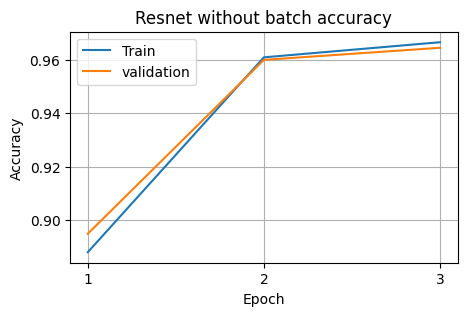

In [ ]:
plt.figure(figsize=(5,3))
train_acc = history_6.history['accuracy']
val_acc = history_6.history['val_accuracy']
plt.plot([1,2,3],train_acc,label='Train')
plt.plot([1,2,3],val_acc,label='validation')
plt.title("Resnet without batch accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)
plt.show()

Training and validation accuracy increased with no clear signs of severe overfitting.

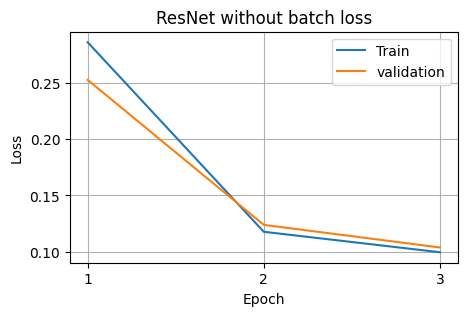

In [ ]:
plt.figure(figsize=(5,3))
train_loss = history_6.history['loss']
val_loss = history_6.history['val_loss']
plt.plot([1,2,3],train_loss,label='Train')
plt.plot([1,2,3],val_loss,label='validation')
plt.title("ResNet without batch loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)
plt.show()

Training and validation loss deacreased over three epochs , indicating effective learning.

In [ ]:
test_generator.reset()
y_prob = model_6.predict(test_generator)
y_pred = np.argmax(y_prob,axis=1)
y_true = test_generator.classes

235/235 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step


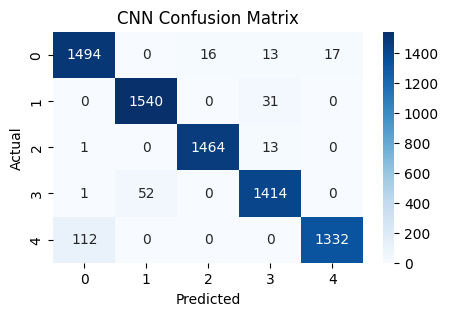

In [ ]:
plt.figure(figsize=(5,3))
cm = confusion_matrix(y_true,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet without BatchNormalization-Confusion Matrix")
plt.show()

The model correctly classified 7244 oyt of 7500 images.

In [ ]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.97      0.95      1540
           1       0.97      0.98      0.97      1571
           2       0.99      0.99      0.99      1478
           3       0.96      0.96      0.96      1467
           4       0.99      0.92      0.95      1444

    accuracy                           0.97      7500
   macro avg       0.97      0.97      0.97      7500
weighted avg       0.97      0.97      0.97      7500



Class 2 achieved the best classification performance with an F1 Score of 0.99.

In [ ]:
transform = transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor()])

The torchvision.transforms module is used to preprocess images before passing them to the neural network.
Resize((224,224)) : Resizes each image to a consistent spatial resolution.
ToTensor() : Converts PIL images into pytorch tensors with shape (C,H,W) and scales pixel values from [0,255] to [0,1].

In [ ]:
class_to_index={'Arborio':0,'Basmati':1,'Ipsala':2,'Jasmine':3,'Karacadag':4}

In [ ]:
class RiceDataset(Dataset):
  def __init__(self,dataframe,transform):
    self.dataframe = dataframe
    self.transform = transform
  def __len__(self):
    return len(self.dataframe)
  def __getitem__(self,index):
    image_path = self.dataframe.iloc[index]['Image_Path']
    image = Image.open(image_path).convert("RGB")
    image = self.transform(image)
    label = self.dataframe.iloc[index]['Class']
    label = class_to_index[label]
    return image , label


A custom RiceDataset class was created by inheriting from torch.utils.data.Dataset.
The class implements three main methods:
__init__() : Stores the dataframe and image transformations.
__len__(): Returns the number of samples.
__getitem__(): Loads an image , converts it to RGB , applies transformations and returns the image tensor with its numerical class label.

In [ ]:
train_dataset = RiceDataset(train_df,transform)

NameError: name 'RiceDataset' is not defined

In [ ]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)

DataLoader objects were used to organize samples into mini-batches for efficient processing.

In [ ]:
valid_dataset = RiceDataset(valid_df,transform)

In [ ]:
valid_loader = DataLoader(valid_dataset,batch_size=32,shuffle=False)

Created a validation dataset and Dataloader using valid_df with a batch size of 32 and shuffle=False to evaluate the model on unseen images.

In [ ]:
images , labels = next(iter(train_loader))
print("images:",images.shape)
print("labels:",labels.shape)

images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


The expected batch dimensions were:
Images : (32,3,224,224)
Labels : (32,)

In [ ]:
class RiceCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3,32,3)
    self.conv2 = nn.Conv2d(32,64,3)
    self.pool = nn.MaxPool2d(2,2)
    self.fc1 = nn.Linear(64*54*54,128)
    self.fc2 = nn.Linear(128,5)

  def forward(self,x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = torch.flatten(x,1)
    x = F.relu(self.fc1(x))
    x = self.fc2(x)
    return x

The architecture consists of:
1 : Two convolutional layers for feature extraction.
2 : Relu activation functions to introduce nonlinearity.
3: MaxPooling layers for spatial downsampling.
4: A flatten operation to convert feature maps into vectors.
5: Two fully connected layers for classification.


In [ ]:
model = RiceCNN()

In [ ]:
x = torch.randn(32,3,224,224)
output = model(x)
print(output.shape)

torch.Size([32, 5])


Tested the CNN using a random input tensor of shape (32,2,224,224).
Output : (32,5)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
model.to(device)

RiceCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=186624, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=5, bias=True)
)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

Trained the CNN using CrossEntropyLoss and Adam optimizer(lr=0.001).

In [ ]:
epochs = 2
for epoch in range(epochs):
  model.train()
  running_loss = 0
  for images , labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs,labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
epoch_loss = running_loss / len(train_loader)
print(f"Epoch {epoch+1}/{epochs} , Loss:{epoch_loss:.4f}")

Epoch 2/2 , Loss:0.0299


Trained the CNN using 2 epochs on GPU.
Final Training Loss : 0.0299

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in valid_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 99.25%


Evaluated the trained CNN on the validation dataset using model.eval() and torch.no_grad(),
The model achieved high accuracy on unseen validation images.

In [ ]:
test_dataset = RiceDataset(test_df,transform)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.11%


Evaluated the trained CNN on the independent test dataset.
Test Accuracy: 99.11%
The model demonstrated strong performance on unseen images.

In [ ]:
torch.save(model.state_dict(),"/content/drive/MyDrive/rice_cnn_pytorch.pth")

In [ ]:
transform = transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor()])

In [ ]:
class_to_index={'Arborio':0,'Basmati':1,'Ipsala':2,'Jasmine':3,'Karacadag':4}

In [ ]:
class AlexNetDataset(Dataset):
  def __init__(self,dataframe,transform):
    self.dataframe = dataframe
    self.transform = transform
  def __len__(self):
    return len(self.dataframe)
  def __getitem__(self,index):
    image_path = self.dataframe.iloc[index]['Image_Path']
    image = Image.open(image_path).convert("RGB")
    image = self.transform(image)
    label = self.dataframe.iloc[index]['Class']
    label = class_to_index[label]
    return image , label


In [ ]:
train_dataset = AlexNetDataset(train_df,transform)

In [ ]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)

In [ ]:
valid_dataset = AlexNetDataset(valid_df,transform)

In [ ]:
valid_loader = DataLoader(valid_dataset,batch_size=32,shuffle=False)

In [ ]:
images , labels = next(iter(train_loader))
print("images:",images.shape)
print("labels:",labels.shape)

images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


In [ ]:
class RiceAlexNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3,64,kernel_size=11,stride=4,padding=2)
    self.pool = nn.MaxPool2d(3,2)
    self.conv2 = nn.Conv2d(64,192,kernel_size=5,padding=2)
    self.conv3 = nn.Conv2d(192,384,3,padding=1)
    self.conv4 = nn.Conv2d(384,256,3,padding=1)
    self.conv5 = nn.Conv2d(256,256,3,padding=1)
    self.fc1 = nn.Linear(9216,4096)
    self.fc2 = nn.Linear(4096,4096)
    self.fc3 = nn.Linear(4096,5)
    self.dropout = nn.Dropout(0.5)
  def forward(self,x):
    x = F.relu(self.conv1(x))
    x = self.pool(x)
    x = F.relu(self.conv2(x))
    x = self.pool(x)
    x = F.relu(self.conv3(x))
    x = F.relu(self.conv4(x))
    x = F.relu(self.conv5(x))
    x = self.pool(x)
    x = torch.flatten(x,1)
    x = F.relu(self.fc1(x))
    x = self.dropout(x)
    x = F.relu(self.fc2(x))
    x = self.dropout(x)
    x = self.fc3(x)
    return x



Implemented a custom AlexNet using pytorch nn.Module , consisting of five convolutional layers and three fully connected layers for classifying five rice varities.
Used ReLU activations and MaxPooling for feature extraction and spatial downsampling.
Final feature map shape : (256,6,6)
Flattened features : 9216
Implemented three linear layers:
FC1 9216 : 4096
FC2 4096 : 4096
FC3 4096 : 5
Applied ReLU and Droput in the classifier.

In [ ]:
model = RiceAlexNet()

In [ ]:
x = torch.randn(32,3,224,224)
output = model(x)
print(output.shape)

torch.Size([32, 5])


Tested the model with a random input tensor of shape (32,3,224,224).
Output shape : (32,5)
The forward pass completed successfully.
The model is ready for training.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
model = model.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

In [ ]:
epochs = 2
for epoch in range(epochs):
  model.train()
  running_loss = 0
  for images , labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs,labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
epoch_loss = running_loss / len(train_loader)
print(f"Epoch {epoch+1}/{epochs} , Loss:{epoch_loss:.4f}")

Epoch 2/2 , Loss:1.6096


Trained AlexNet for 2 Epochs using CrossEntropyLoss and Adam on GPU.
Final Training Loss : 1.6096

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in valid_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 20.25%


Evaluated AlexNet on the validation and test datasets.
Validation Accuracy:20.25%
Test Accuracy:19.25%
Performance remained close to random guessing for five balanced classes indicating limited learning.

In [ ]:
test_dataset = AlexNetDataset(test_df,transform)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 19.25%


Evaluated the trained AlexNet on the independent test dataset using model.eval() and torch.no_grad().
Test Accuracy: 19.25%
The model performanced close to random guessing, indicating that further optimization is needed.

In [ ]:
torch.save(model.state_dict(),"/content/drive/MyDrive/rice_alexnet_pytorch.pth")

In [ ]:
class AlexNetDataset2(Dataset):
  def __init__(self,dataframe,transform):
    self.dataframe = dataframe
    self.transform = transform
  def __len__(self):
    return len(self.dataframe)
  def __getitem__(self,index):
    image_path = self.dataframe.iloc[index]['Image_Path']
    image = Image.open(image_path).convert("RGB")
    image = self.transform(image)
    label = self.dataframe.iloc[index]['Class']
    label = class_to_index[label]
    return image , label


In [ ]:
train_dataset = AlexNetDataset2(train_df,transform)

In [ ]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)

In [ ]:
valid_dataset = AlexNetDataset2(valid_df,transform)

In [ ]:
valid_loader = DataLoader(valid_dataset,batch_size=32,shuffle=False)

In [ ]:
images , labels = next(iter(train_loader))
print("images:",images.shape)
print("labels:",labels.shape)

images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


In [ ]:
class RiceAlexNet2(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3,96,kernel_size=11,stride=4,padding=1)
    self.conv2 = nn.Conv2d(96,256,kernel_size=5,stride=1,padding=2,groups=2)
    self.conv3 = nn.Conv2d(256,384,kernel_size=3,stride=1,padding=1)
    self.conv4 = nn.Conv2d(384,384,kernel_size=3,stride=1,padding=1,groups=2)
    self.conv5 = nn.Conv2d(384,256,kernel_size=2,stride=1,padding=1,groups=2)
    self.pool = nn.MaxPool2d(kernel_size=3,stride=2)
    self.lrn = nn.LocalResponseNorm(size=5,alpha=1e-4,beta=0.75,k=2)
    self.fc1 = nn.Linear(9216,4096)
    self.fc2 = nn.Linear(4096,4096)
    self.fc3 = nn.Linear(4096,5)
    self.dropout = nn.Dropout(0.5)
  def forward(self,x):
    x = F.relu(self.conv1(x))
    x = self.lrn(x)
    x = self.pool(x)
    x = F.relu(self.conv2(x))
    x = self.lrn(x)
    x = self.pool(x)
    x = F.relu(self.conv3(x))
    x = F.relu(self.conv4(x))
    x = F.relu(self.conv5(x))
    x = self.pool(x)
    x = torch.flatten(x,start_dim=1)
    x = F.relu(self.fc1(x))
    x = self.dropout(x)
    x = F.relu(self.fc2(x))
    x = self.dropout(x)
    x = self.fc3(x)
    return x

This cell implements an AlexNet based CNN with five convolutional layers , ReLU,LRN,MaxPooling and three fully connected layers.
Dropout(0.5) helps prevent overfitting. The model outputs five logits for rice classification without softmax.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RiceAlexNet2().to(device)
sample = torch.randn(1,3,224,224,device=device)
model.eval()
with torch.no_grad():
  output = model(sample)
print(output.shape)

torch.Size([1, 5])


The AlexNet model is initialized and moved to the available device.
A random input tensor of shape (1,3,224,224) was used to verify model's output dimensions.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.0001)

CrossEntropyLoss is used for multiclass classification while the Adam optimizer updates model weights with a learning rate of 0.0001.

In [ ]:
epochs = 2
for epoch in range(epochs):
  model.train()
  running_loss = 0
  for images , labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs,labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
epoch_loss = running_loss / len(train_loader)
print(f"Epoch {epoch+1}/{epochs} , Loss:{epoch_loss:.4f}")

Epoch 2/2 , Loss:0.1096


The model was trained for 2 epochs using forward propagation, loss calculation, backpropagation and weights updates.

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in valid_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 97.01%


The model was evaluated on the validation dataset using evaluation mode and disabled gradient computation.

In [ ]:
test_dataset = AlexNetDataset2(test_df,transform)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

In [ ]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.13%


The trained model was evaluated on the test dataset to assess its performance on unseen images.

In [ ]:
torch.save(model.state_dict(),'/content/drive/MyDrive/Rice_AlexNet2_pytorch.pth')

In [18]:
transform = transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor()])

In [19]:
class_to_index={'Arborio':0,'Basmati':1,'Ipsala':2,'Jasmine':3,'Karacadag':4}

In [20]:
class ResNetDataset(Dataset):
  def __init__(self,dataframe,transform):
    self.dataframe = dataframe
    self.transform = transform
  def __len__(self):
    return len(self.dataframe)
  def __getitem__(self,index):
    image_path = self.dataframe.iloc[index]['Image_Path']
    image = Image.open(image_path).convert("RGB")
    image = self.transform(image)
    label = self.dataframe.iloc[index]['Class']
    label = class_to_index[label]
    return image , label


In [21]:
train_dataset = ResNetDataset(train_df,transform)

In [22]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)

In [23]:
valid_dataset = ResNetDataset(valid_df,transform)

In [24]:
valid_loader = DataLoader(valid_dataset,batch_size=32,shuffle=False)

In [25]:
images , labels = next(iter(train_loader))
print("images:",images.shape)
print("labels:",labels.shape)

images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


In [26]:
class BasicBlock(nn.Module):
  def __init__(self,in_channels,out_channels,stride=1):
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels,out_channels,kernel_size=3,stride=stride,padding=1,bias=False)
    self.bn1 = nn.BatchNorm2d(out_channels)
    self.conv2 = nn.Conv2d(in_channels=out_channels,out_channels=out_channels,kernel_size=3,stride=1,padding=1,bias=False)
    self.bn2 = nn.BatchNorm2d(out_channels)
    if (stride!=1 or in_channels != out_channels):
      self.shortcut_conv = nn.Conv2d(in_channels=in_channels,out_channels=out_channels,kernel_size=1,stride=stride,bias=False)
      self.bn3 = nn.BatchNorm2d(out_channels)
    else:
      self.shortcut_conv = None
  def forward(self,x):
    identity_shortcut = x
    x = F.relu(self.bn1(self.conv1(x)))
    x = self.bn2(self.conv2(x))
    if self.shortcut_conv is not None:
      identity_shortcut = self.bn3(self.shortcut_conv(identity_shortcut))
    x = x + identity_shortcut
    x = F.relu(x)
    return x

A residual block was implemented using 2 convolutional layers , batch normalization , relu and a shortcut connections. 1*1 convolution adjusts the shortcut when dimensions differ.

In [28]:
class ResNet18(nn.Module):
  def __init__(self,num_classes=5):
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels=3,out_channels=64,kernel_size=7, stride=2, padding=3,bias=False)
    self.bn1 = nn.BatchNorm2d(64)
    self.maxpool = nn.MaxPool2d(kernel_size=3,stride=2,padding=1)
    self.layer1 = nn.Sequential(BasicBlock(64,64),BasicBlock(64,64))
    self.layer2 = nn.Sequential(BasicBlock(64,128,stride=2),BasicBlock(128,128))
    self.layer3 = nn.Sequential(BasicBlock(128,256,stride=2),BasicBlock(256,256))
    self.layer4 = nn.Sequential(BasicBlock(256,512,stride=2),BasicBlock(512,512))
    self.avgpool = nn.AdaptiveAvgPool2d((1,1))
    self.fc = nn.Linear(512,num_classes)
  def forward(self,x):
    x = F.relu(self.bn1(self.conv1(x)))
    x = self.maxpool(x)
    x = self.layer1(x)
    x = self.layer2(x)
    x = self.layer3(x)
    x = self.layer4(x)
    x = self.avgpool(x)
    x= torch.flatten(x,1)
    x = self.fc(x)
    return x

ResNet18 was built from scratch using an initial convolutional layer and four residual stages containing two BasicBlocks each. Global Average Pooling and a fully connected layer produce five output logits.

In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet18().to(device)
sample = torch.randn(1,3,224,224,device=device)
model.eval()
with torch.no_grad():
  output = model(sample)
print(output.shape)

torch.Size([1, 5])


The model was moved to the available device and tested using a random input tensor of shape (1,3,224,224). The output shape (1,5) confirms five classification logits.

In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.0001)

In [31]:
epochs = 2
for epoch in range(epochs):
  model.train()
  running_loss = 0
  for images , labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs,labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
epoch_loss = running_loss / len(train_loader)
print(f"Epoch {epoch+1}/{epochs} , Loss:{epoch_loss:.4f}")

Epoch 2/2 , Loss:0.0288


The Resnet-18 model was trained for 2 epochs using backpropagation and optimizer updates.
The final training loss was 0.0288, indicating a low training error.

In [32]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in valid_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 99.33%


The trained ResNet18 model achieved 99.33% validation accuracy, demonstrating strong performance on unseen validation images.

In [35]:
test_dataset = ResNetDataset(test_df,transform)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

In [36]:
correct = 0
total = 0
model.eval()
with torch.no_grad():
  for images , labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    _ , predicted = torch.max(outputs,1)
    correct += (predicted == labels).sum().item()
    total += labels.size(0)
accuracy = correct / total * 100
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.40%


The ResNet18 model achieved 99.40% test accuracy, demonstrating excellent generalization to unseen test images.

In [37]:
torch.save(model.state_dict(),'/content/drive/MyDrive/rice_resnet18.pth')